# Notebook 5 — Visualisasi Spasial Terpadu, Peta per Kejadian (Per-Event Maps), dan Sintesis Oseanografi

**Proyek:** Analisis Spatiotemporal Marine Heatwaves (MHW), Klorofil-a, dan Konteks Perikanan Tangkap Provinsi Nusa Tenggara Timur  
**Dokumen Rujukan Metodologis:** `REVISI_PBL.md` (Bagian 8.1 & 8.2)

---

## 1. Tujuan dan Standar Visualisasi

1. **Sintesis Komposit 2000–2020:** Menggambarkan variabilitas SST, anomali termal, dan respons klorofil-a lintas dekade di NTT.
2. **Peta Spasial per Kejadian (Per-Event Maps — Mandat Utama PRD):**
   - Menghasilkan visualisasi resolusi tinggi untuk 3 kejadian MHW paling masif di perairan NTT:
     - **Peta A (Luas Sebaran):** Sel-sel perairan yang teridentifikasi mengalami kondisi MHW selama kejadian.
     - **Peta B (Intensitas Maksimum):** Suhu anomali puncak ($^\circ\text{C}$ di atas klimatologi) pada masing-masing sel grid.
     - **Peta C (Durasi Lokal):** Jumlah hari aktif MHW pada masing-masing sel grid selama kejadian berlangsung.
3. **Penyelarasan Kartografi:** Menggunakan skala warna perceptually-uniform, rasio aspek geografis presisi, dan garis kontur pulau-pulau utama NTT.


---
## 1. Konfigurasi dan Pengaturan Gaya Visual

In [1]:
import sys
import os
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

notebook_dir = Path(os.path.abspath(''))
project_root = notebook_dir.parent if notebook_dir.name == 'notebooks' else notebook_dir
sys.path.insert(0, str(project_root))
sys.path.insert(0, str(project_root / 'config'))

import project_config as cfg

# Pengaturan Global Matplotlib untuk Kualitas Publikasi
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = cfg.FIGURE_DPI

print("Pengaturan visualisasi standar publikasi siap.")

Pengaturan visualisasi standar publikasi siap.


---
## 2. Pemuatan Seluruh Dataset Hasil Analisis Terverifikasi

In [2]:
# Pemuatan data terpadu
print("Memuat dataset untuk visualisasi dan sintesis spasial...")
ds_sst = xr.open_dataset(cfg.SST_MERGED_OUTPUT)
ds_chla = xr.open_dataset(cfg.CHLA_MERGED_OUTPUT)
ds_spatial_mhw = xr.open_dataset(cfg.SST_CLIMATOLOGY_OUTPUT)
ds_combined = xr.open_dataset(cfg.COMBINED_OUTPUT)

df_events = pd.read_csv(cfg.MHW_EVENTS_OUTPUT)
df_annual_mhw = pd.read_csv(cfg.MHW_METRICS_OUTPUT)

# Buka katalog spasial regional jika ada
catalog_file = cfg.TABLES_DIR / "mhw_events_spatial_catalog_ntt.csv"
if not catalog_file.exists():
    catalog_file = cfg.PROCESSED_DIR / "mhw_events_spatial_catalog_ntt.csv"

if catalog_file.exists():
    df_reg_events = pd.read_csv(catalog_file)
    print(f"✅ Katalog MHW Regional Spasial: {len(df_reg_events)} kejadian.")
else:
    df_reg_events = df_events

print(f"✅ Seluruh dataset berhasil dimuat ke memori.")


Memuat dataset untuk visualisasi dan sintesis spasial...


✅ Katalog MHW Regional Spasial: 56 kejadian.
✅ Seluruh dataset berhasil dimuat ke memori.


---
## 3. Figur Sintesis 1: Karakteristik Termal dan Siklus Musiman SST (2000–2020)

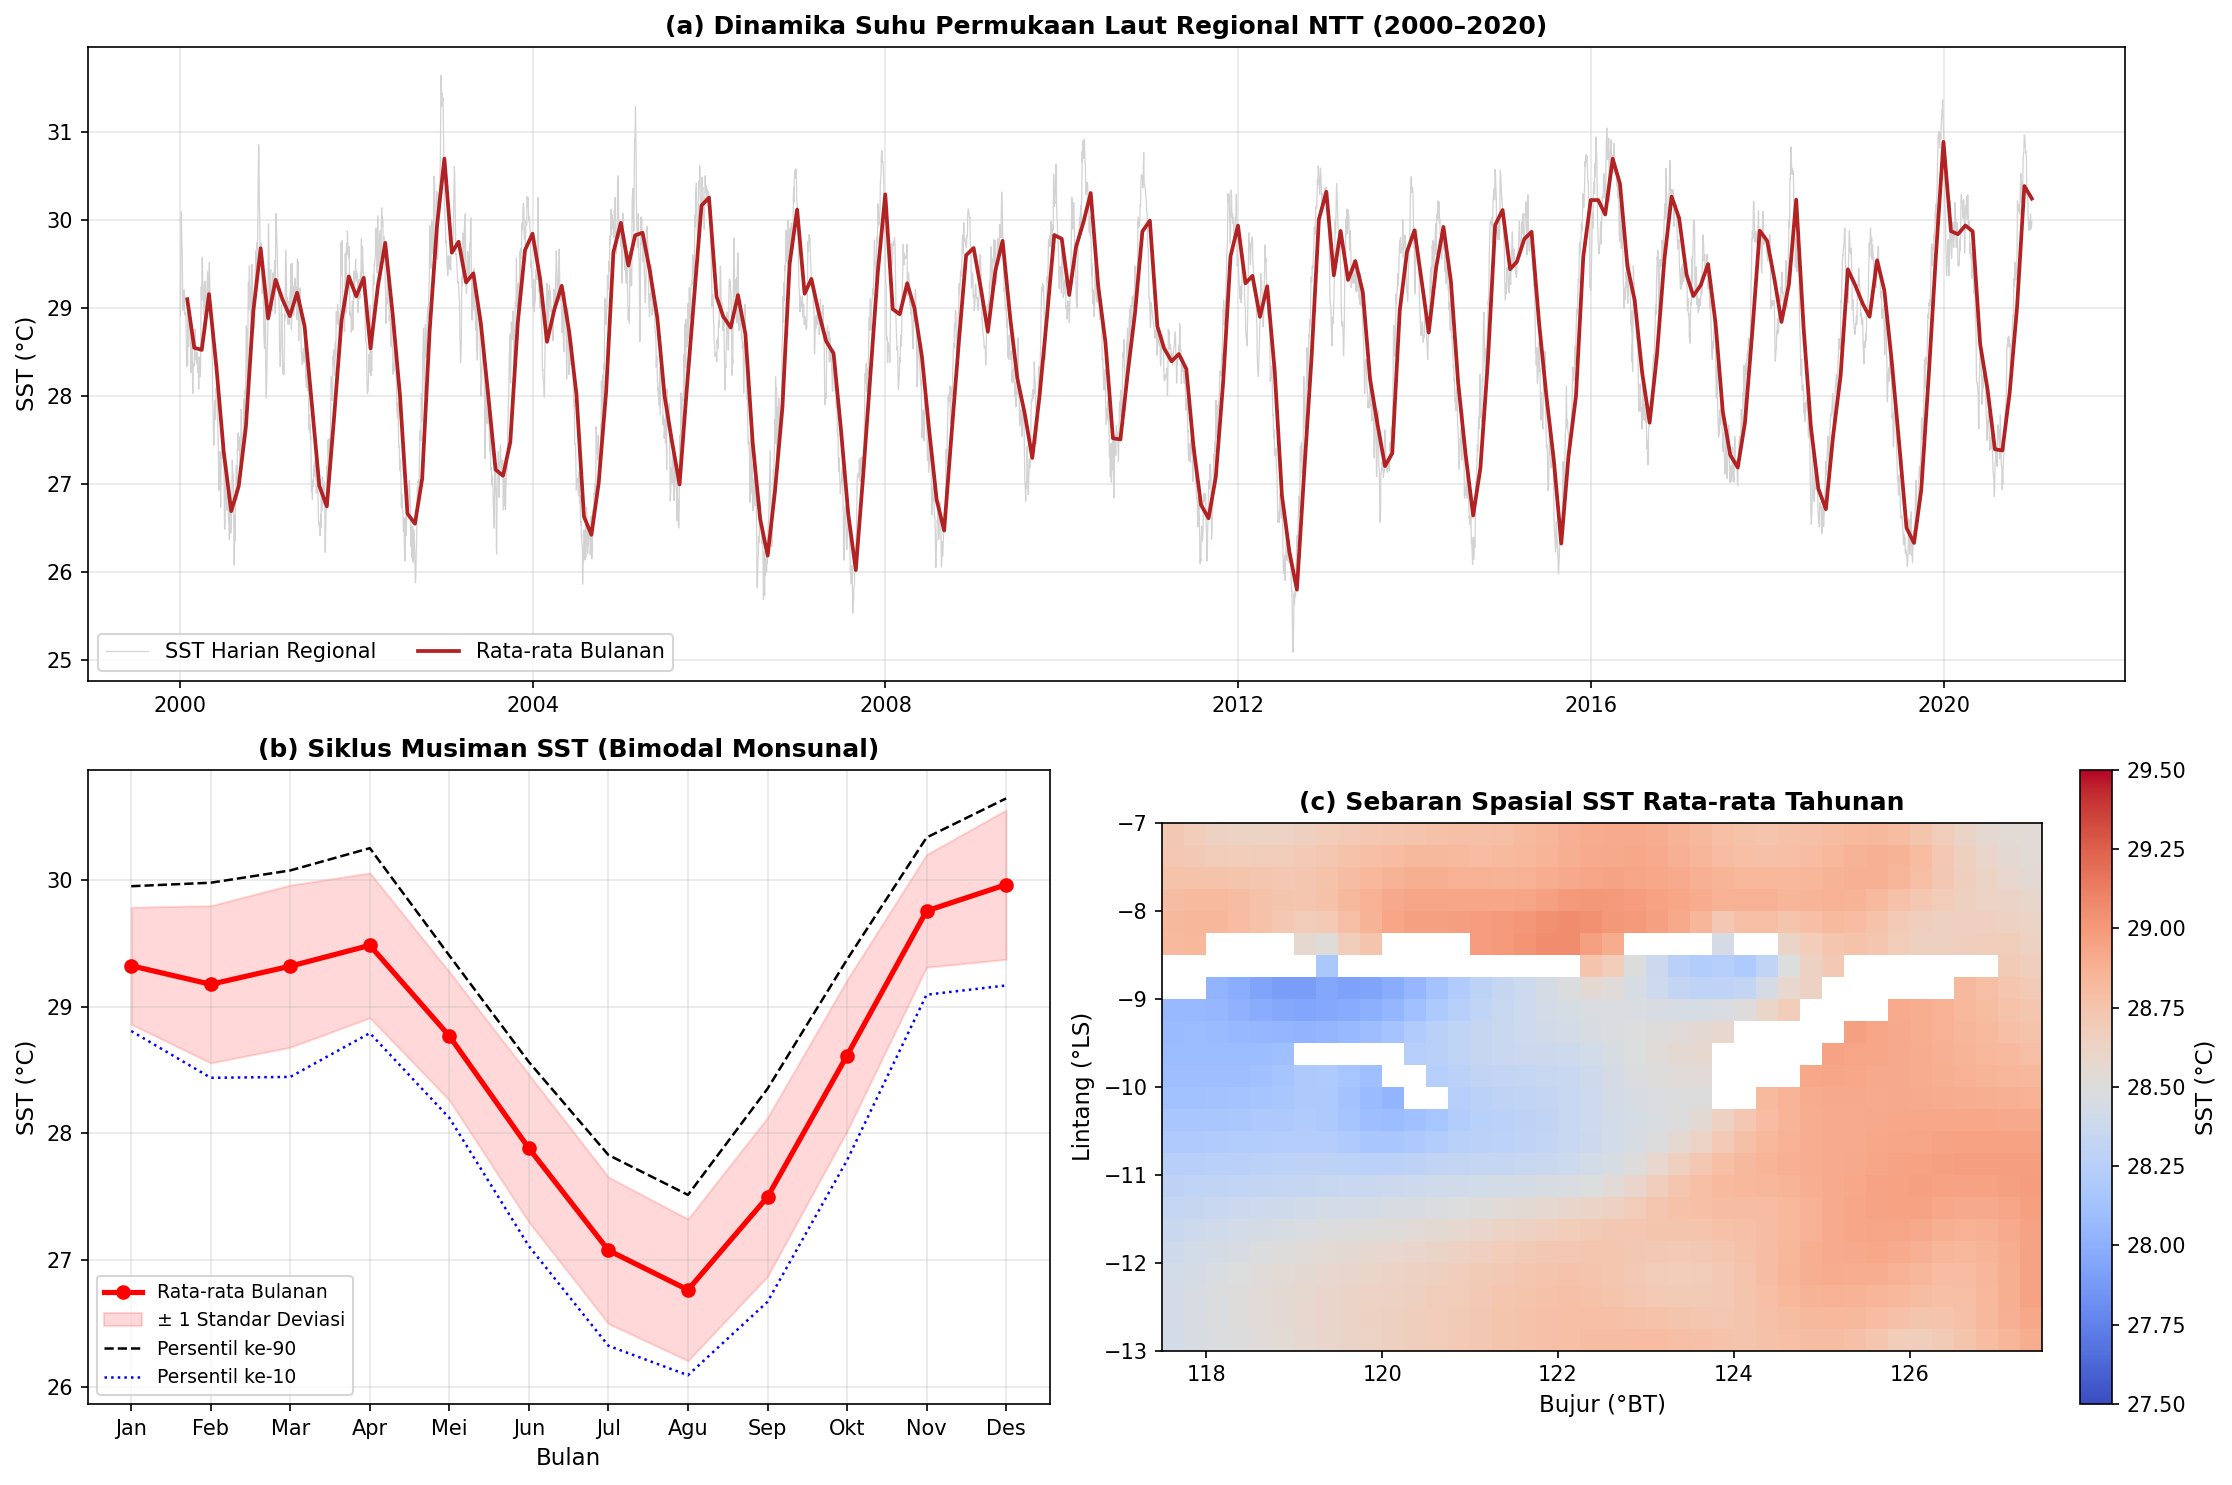

Figur 1 disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\fig1_sintesis_karakteristik_sst.png


In [3]:
fig = plt.figure(figsize=(15, 10))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 1], figure=fig)

# Deret waktu SST harian regional
sst_mean_ts = ds_sst['sst'].mean(dim=['lat', 'lon'], skipna=True).to_series()
sst_monthly_mean = sst_mean_ts.resample('ME').mean()

# Panel (a): Deret Waktu Lengkap SST Harian & Bulanan
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(sst_mean_ts.index, sst_mean_ts.values, color='lightgrey', lw=0.6, label='SST Harian Regional')
ax1.plot(sst_monthly_mean.index, sst_monthly_mean.values, color='firebrick', lw=1.8, label='Rata-rata Bulanan')
ax1.set_ylabel('SST (°C)')
ax1.set_title('(a) Dinamika Suhu Permukaan Laut Regional NTT (2000–2020)', fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower left', ncol=2)

# Panel (b): Siklus Musiman Bulanan
ax2 = fig.add_subplot(gs[1, 0])
monthly_stats = sst_mean_ts.groupby(sst_mean_ts.index.month).agg(['mean', 'std', lambda x: x.quantile(0.9), lambda x: x.quantile(0.1)])
monthly_stats.columns = ['mean', 'std', 'p90', 'p10']
months = range(1, 13)
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

ax2.plot(months, monthly_stats['mean'], 'ro-', lw=2.5, label='Rata-rata Bulanan')
ax2.fill_between(months, monthly_stats['mean'] - monthly_stats['std'],
                 monthly_stats['mean'] + monthly_stats['std'], color='red', alpha=0.15, label='± 1 Standar Deviasi')
ax2.plot(months, monthly_stats['p90'], 'k--', lw=1.2, label='Persentil ke-90')
ax2.plot(months, monthly_stats['p10'], 'b:', lw=1.2, label='Persentil ke-10')
ax2.set_xticks(months)
ax2.set_xticklabels(month_labels)
ax2.set_xlabel('Bulan')
ax2.set_ylabel('SST (°C)')
ax2.set_title('(b) Siklus Musiman SST (Bimodal Monsunal)', fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='lower left', fontsize=9)

# Panel (c): Peta SST Rata-rata Tahunan (Spasial)
ax3 = fig.add_subplot(gs[1, 1])
sst_annual_map = ds_sst['sst'].mean(dim='time')
im3 = ax3.pcolormesh(ds_sst.lon, ds_sst.lat, sst_annual_map, cmap=cfg.COLORMAP_SST,
                     vmin=27.5, vmax=29.5, shading='auto')
ax3.set_xlabel('Bujur (°BT)')
ax3.set_ylabel('Lintang (°LS)')
ax3.set_title('(c) Sebaran Spasial SST Rata-rata Tahunan', fontweight='bold')
ax3.set_aspect('equal')
cb3 = plt.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)
cb3.set_label('SST (°C)')

plt.tight_layout()
fig_path = cfg.FIGURES_DIR / "fig1_sintesis_karakteristik_sst.png"
fig.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f"Figur 1 disimpan: {fig_path}")

---
## 4. Figur Sintesis 2: Garis Waktu dan Evolusi Tahunan Marine Heatwave (2000–2020)

C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_28072\3485907769.py:7: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  sst_doy = sst_mean_ts.groupby(sst_mean_ts.index.dayofyear).transform('mean')


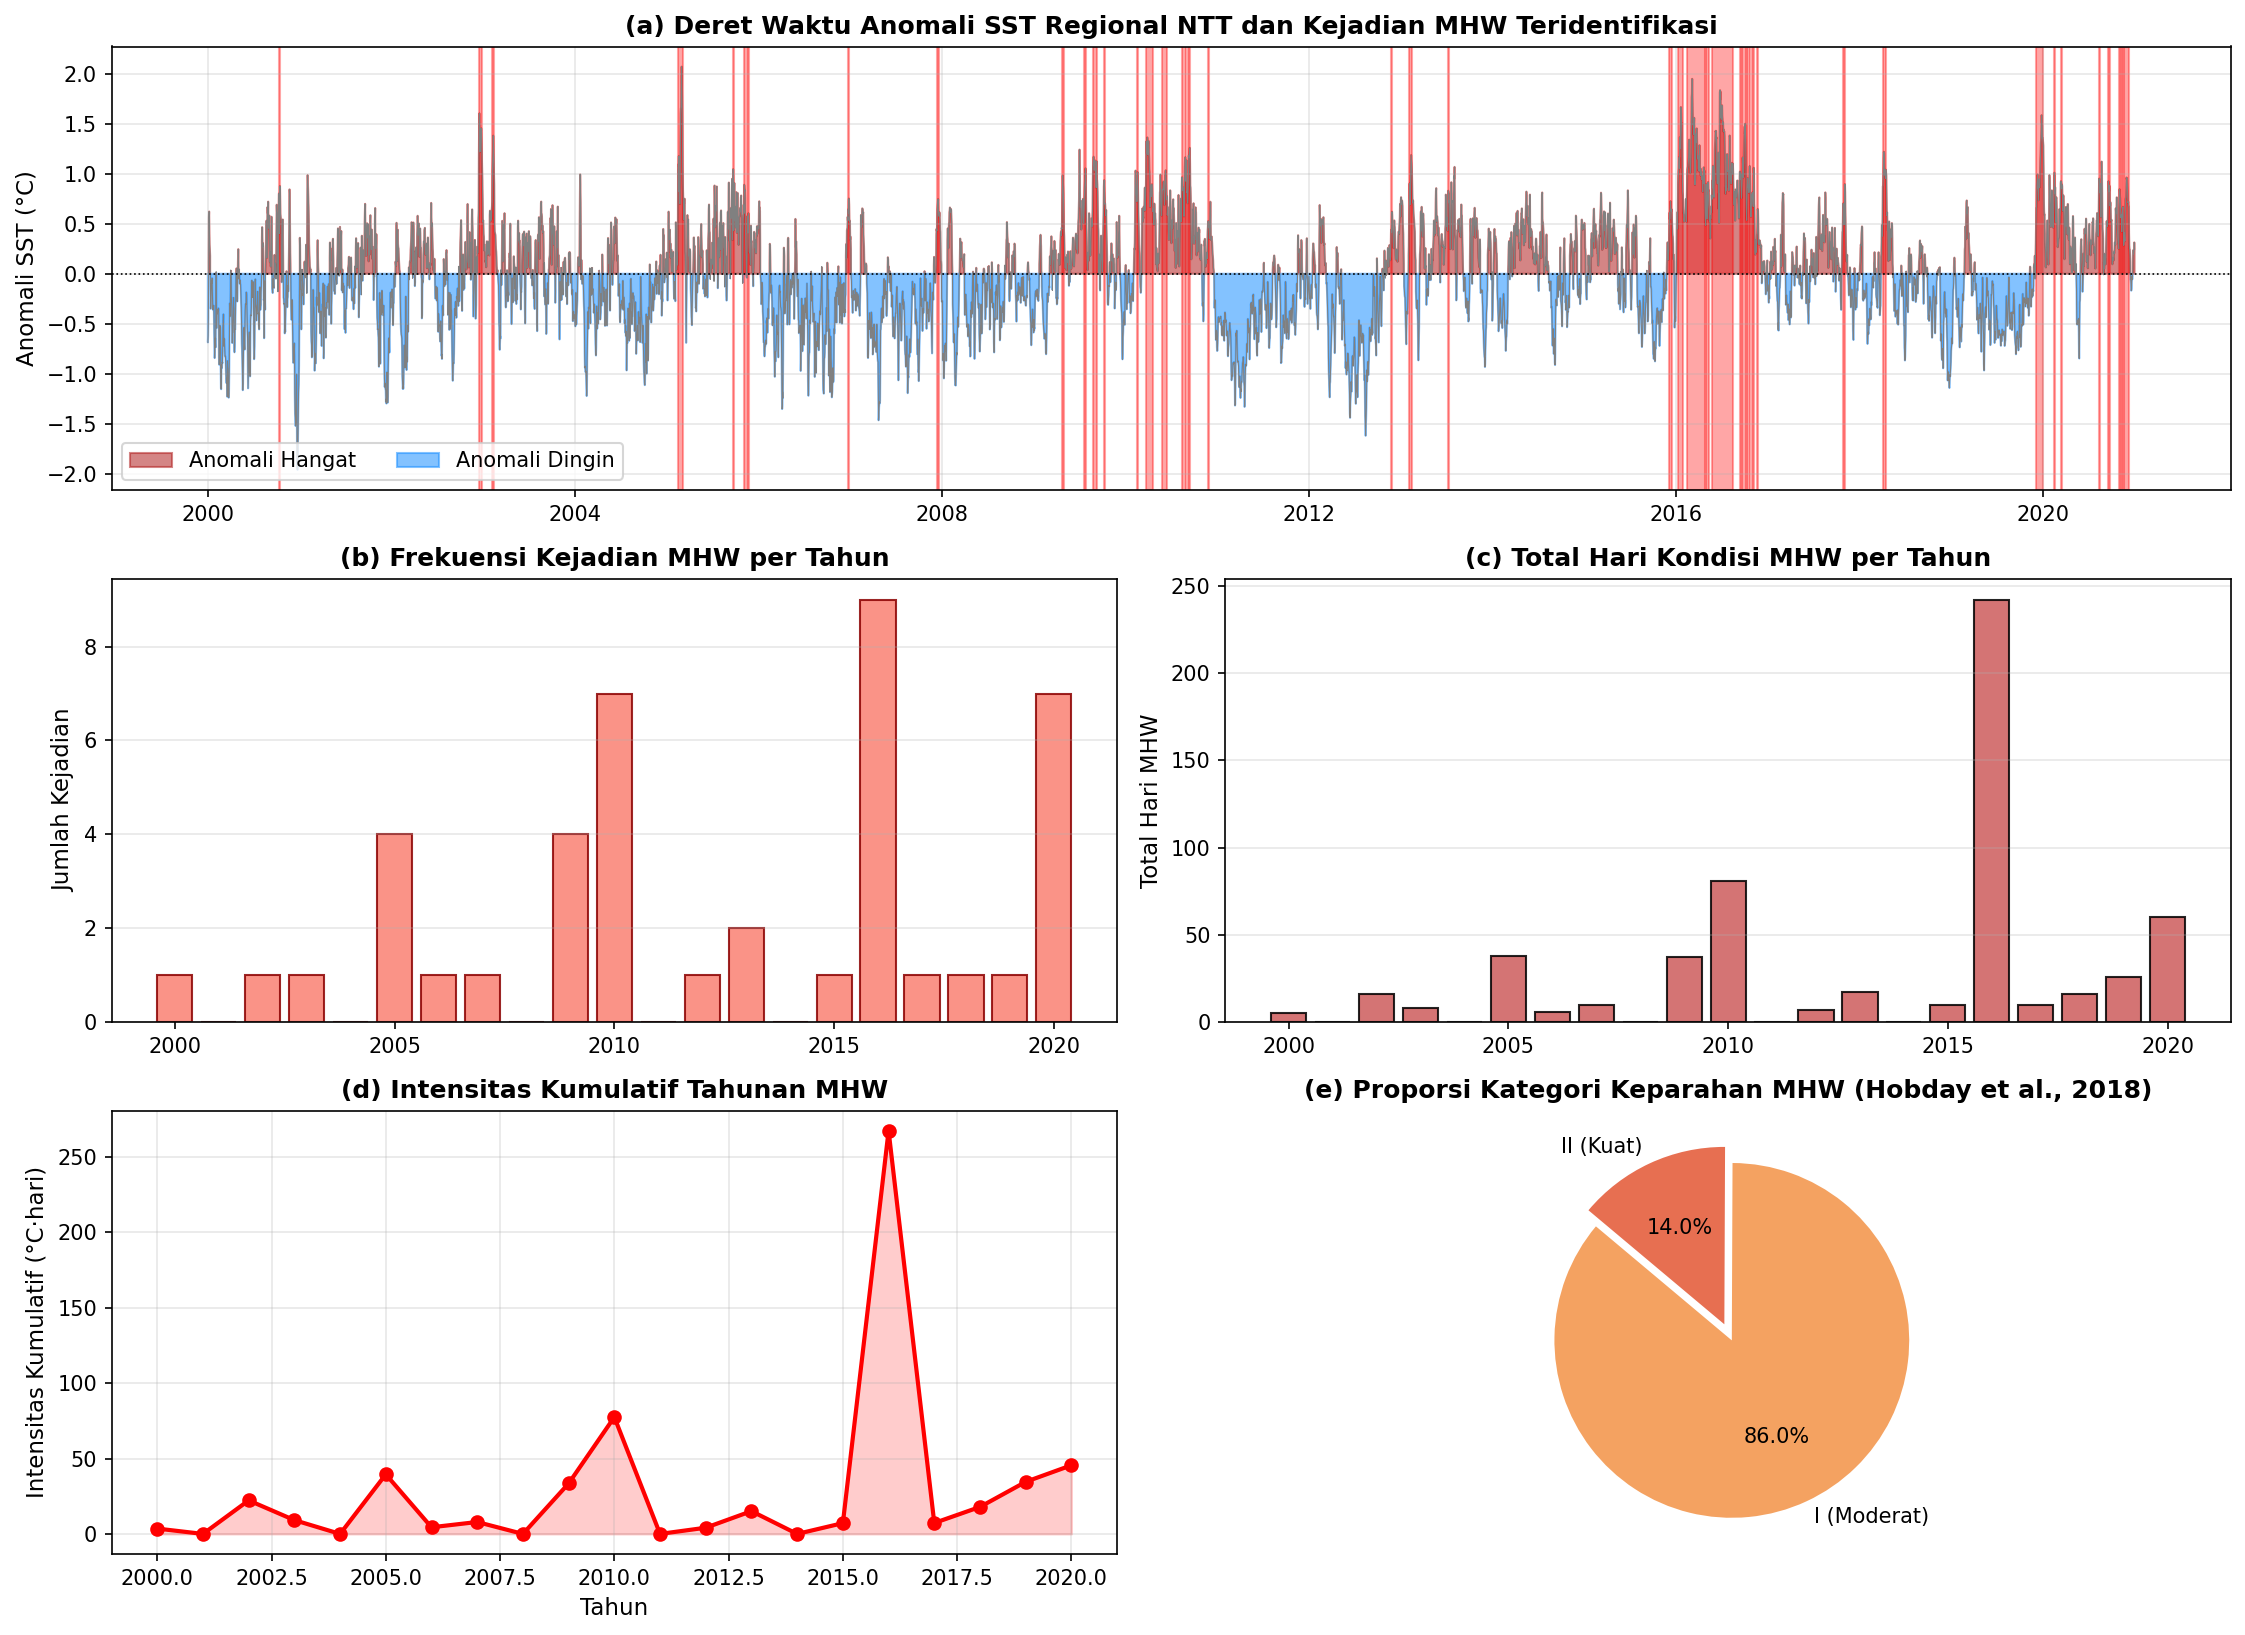

Figur 2 disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\fig2_sintesis_timeline_mhw.png


In [4]:
fig = plt.figure(figsize=(15, 11))
gs = gridspec.GridSpec(3, 2, figure=fig)

# Panel (a): Timeline Kejadian MHW (Frekuensi & Anomali)
ax1 = fig.add_subplot(gs[0, :])
# Ambil anomali dari sst_mean_ts
sst_doy = sst_mean_ts.groupby(sst_mean_ts.index.dayofyear).transform('mean')
sst_anom = sst_mean_ts - sst_doy

ax1.plot(sst_anom.index, sst_anom.values, color='grey', lw=0.5)
ax1.fill_between(sst_anom.index, 0, sst_anom.values, where=(sst_anom.values > 0),
                 color='firebrick', alpha=0.55, label='Anomali Hangat')
ax1.fill_between(sst_anom.index, 0, sst_anom.values, where=(sst_anom.values <= 0),
                 color='dodgerblue', alpha=0.55, label='Anomali Dingin')

for _, ev in df_events.iterrows():
    s = pd.to_datetime(ev['start_date'])
    e = pd.to_datetime(ev['end_date'])
    ax1.axvspan(s, e, color='red', alpha=0.35)

ax1.set_ylabel('Anomali SST (°C)')
ax1.set_title('(a) Deret Waktu Anomali SST Regional NTT dan Kejadian MHW Teridentifikasi', fontweight='bold')
ax1.axhline(0, color='black', lw=0.8, ls=':')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower left', ncol=3)

# Panel (b): Frekuensi Kejadian per Tahun
ax2 = fig.add_subplot(gs[1, 0])
ax2.bar(df_annual_mhw['tahun'], df_annual_mhw['frekuensi_kejadian'],
        color='salmon', edgecolor='darkred', alpha=0.85)
ax2.set_ylabel('Jumlah Kejadian')
ax2.set_title('(b) Frekuensi Kejadian MHW per Tahun', fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')

# Panel (c): Total Hari MHW per Tahun
ax3 = fig.add_subplot(gs[1, 1])
ax3.bar(df_annual_mhw['tahun'], df_annual_mhw['total_hari_mhw'],
        color='indianred', edgecolor='black', alpha=0.85)
ax3.set_ylabel('Total Hari MHW')
ax3.set_title('(c) Total Hari Kondisi MHW per Tahun', fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')

# Panel (d): Intensitas Kumulatif Tahunan
ax4 = fig.add_subplot(gs[2, 0])
ax4.plot(df_annual_mhw['tahun'], df_annual_mhw['intensitas_kumulatif_tahunan'], 'ro-', lw=2)
ax4.fill_between(df_annual_mhw['tahun'], 0, df_annual_mhw['intensitas_kumulatif_tahunan'], color='red', alpha=0.2)
ax4.set_xlabel('Tahun')
ax4.set_ylabel('Intensitas Kumulatif (°C·hari)')
ax4.set_title('(d) Intensitas Kumulatif Tahunan MHW', fontweight='bold')
ax4.grid(True, alpha=0.3)

# Panel (e): Proporsi Kejadian per Kategori Keparahan
ax5 = fig.add_subplot(gs[2, 1])
cat_counts = df_events['category'].value_counts()
colors_cat = ['#f4a261', '#e76f51', '#d62828', '#6a040f']
ax5.pie(cat_counts, labels=cat_counts.index, autopct='%1.1f%%',
        startangle=140, colors=colors_cat[:len(cat_counts)], explode=[0.05]*len(cat_counts))
ax5.set_title('(e) Proporsi Kategori Keparahan MHW (Hobday et al., 2018)', fontweight='bold')

plt.tight_layout()
fig_path = cfg.FIGURES_DIR / "fig2_sintesis_timeline_mhw.png"
fig.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f"Figur 2 disimpan: {fig_path}")

---
## 5. Figur Sintesis 3: Sebaran Spasial Multi-Parameter di Perairan NTT

✅ Gambar 3 disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\fig3_sintesis_spasial_multiparameter.png


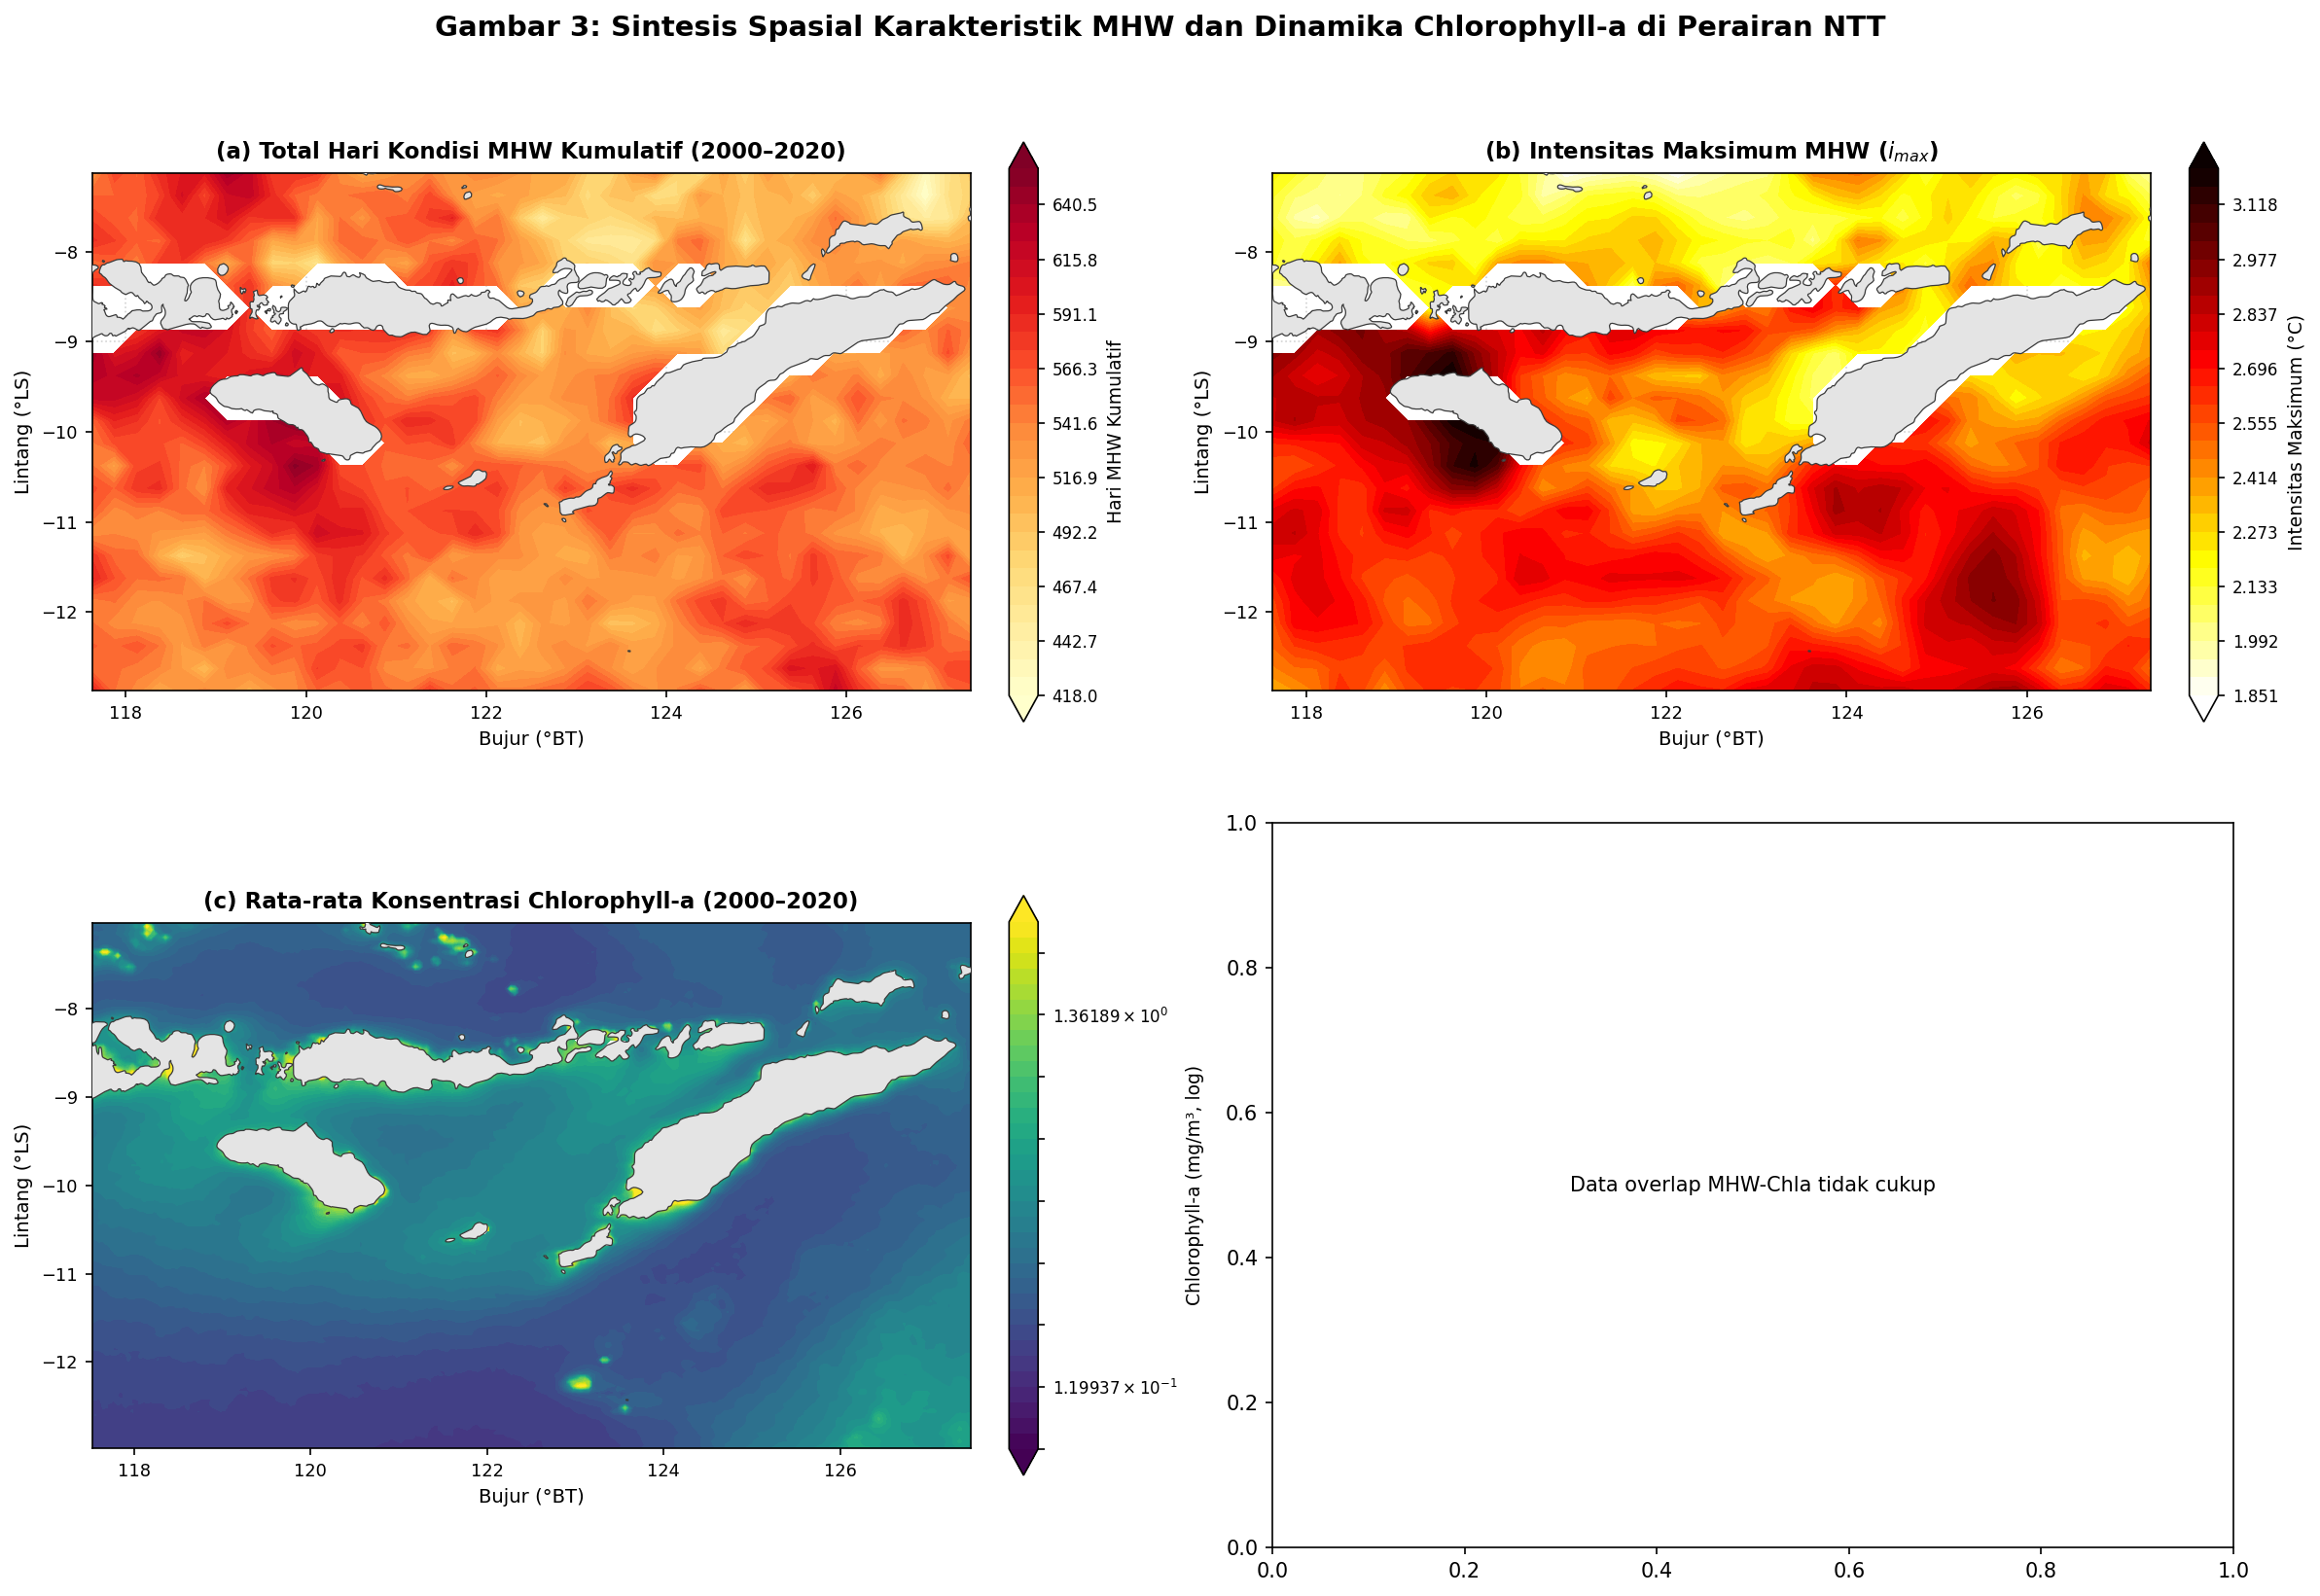

In [5]:
# Gambar 3: Sintesis Spasial Multiparameter (MHW dan Respons Klorofil-a)
from scripts.visualization_utils import plot_smooth_map, load_ntt_coastline

gdf_land = load_ntt_coastline()
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Panel (a): Total Hari MHW Spasial Kumulatif (Kontinu)
cs1, cb1 = plot_smooth_map(
    axes[0, 0], ds_spatial_mhw.lon.values, ds_spatial_mhw.lat.values, ds_spatial_mhw['total_mhw_days'].values,
    var_type="continuous", cmap='YlOrRd', levels=30,
    title='(a) Total Hari Kondisi MHW Kumulatif (2000–2020)',
    cbar_label='Hari MHW Kumulatif', gdf_land=gdf_land
)

# Panel (b): Intensitas Maksimum MHW (Kontinu)
cs2, cb2 = plot_smooth_map(
    axes[0, 1], ds_spatial_mhw.lon.values, ds_spatial_mhw.lat.values, ds_spatial_mhw['max_intensity'].values,
    var_type="continuous", cmap='hot_r', levels=30,
    title='(b) Intensitas Maksimum MHW ($i_{max}$)',
    cbar_label='Intensitas Maksimum (°C)', gdf_land=gdf_land
)

# Panel (c): Rata-rata Spasial Chlorophyll-a (Skala Logaritmik)
chla_spatial_mean = ds_chla['chlor_a'].mean(dim='time', skipna=True).values
cs3, cb3 = plot_smooth_map(
    axes[1, 0], ds_chla.lon.values, ds_chla.lat.values, chla_spatial_mean,
    var_type="log", cmap=cfg.COLORMAP_CHLA, vmin=0.08, vmax=2.5, levels=35,
    title='(c) Rata-rata Konsentrasi Chlorophyll-a (2000–2020)',
    cbar_label='Chlorophyll-a (mg/m³, log)', gdf_land=gdf_land
)

# Panel (d): Anomali Chlorophyll-a Komposit Periode MHW
mhw_dates = pd.to_datetime(df_events['start_date'])
mhw_in_overlap = df_events[pd.to_datetime(df_events['end_date']) <= '2020-12-31']

mhw_all_times = []
for _, row in mhw_in_overlap.iterrows():
    mhw_all_times.extend(pd.date_range(row['start_date'], row['end_date']))

mhw_times_dt64 = np.array(list(set(mhw_all_times)), dtype='datetime64[ns]')
common_mhw_times = np.intersect1d(ds_combined.time.values, mhw_times_dt64)

if len(common_mhw_times) > 0:
    chla_during_mhw = ds_combined['chlor_a'].sel(time=common_mhw_times).mean(dim='time')
    chla_clim_all = ds_combined['chlor_a'].mean(dim='time')
    chla_anom_mhw = (chla_during_mhw - chla_clim_all).values
    
    cs4, cb4 = plot_smooth_map(
        axes[1, 1], ds_combined.lon.values, ds_combined.lat.values, chla_anom_mhw,
        var_type="continuous", cmap='BrBG', vmin=-0.15, vmax=0.15, levels=30,
        title='(d) Rata-rata Anomali Chlorophyll-a saat Periode MHW',
        cbar_label='Anomali Chl-a (mg/m³)', gdf_land=gdf_land
    )
else:
    axes[1, 1].text(0.5, 0.5, "Data overlap MHW-Chla tidak cukup", ha='center', va='center')

plt.suptitle('Gambar 3: Sintesis Spasial Karakteristik MHW dan Dinamika Chlorophyll-a di Perairan NTT',
             fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
fig_path = cfg.FIGURES_DIR / "fig3_sintesis_spasial_multiparameter.png"
fig.savefig(fig_path, bbox_inches='tight')
print(f"✅ Gambar 3 disimpan: {fig_path}")
plt.show()


---
## 6. Figur Sintesis 4: Perbandingan dan Respon Biologis Chlorophyll-a Terhadap MHW

Ringkasan Perbandingan MHW vs Non-MHW:
   Kondisi  N_Hari  Chla_Mean  Chla_Median  Chla_Std  Chla_IQR  Anomali_Mean  \
0      MHW     545     0.2217       0.2055    0.0559    0.0608       -0.0516   
1  Non-MHW    7036     0.2903       0.2633    0.1117    0.1491        0.0040   

   Anomali_Median  
0         -0.0454  
1         -0.0036  


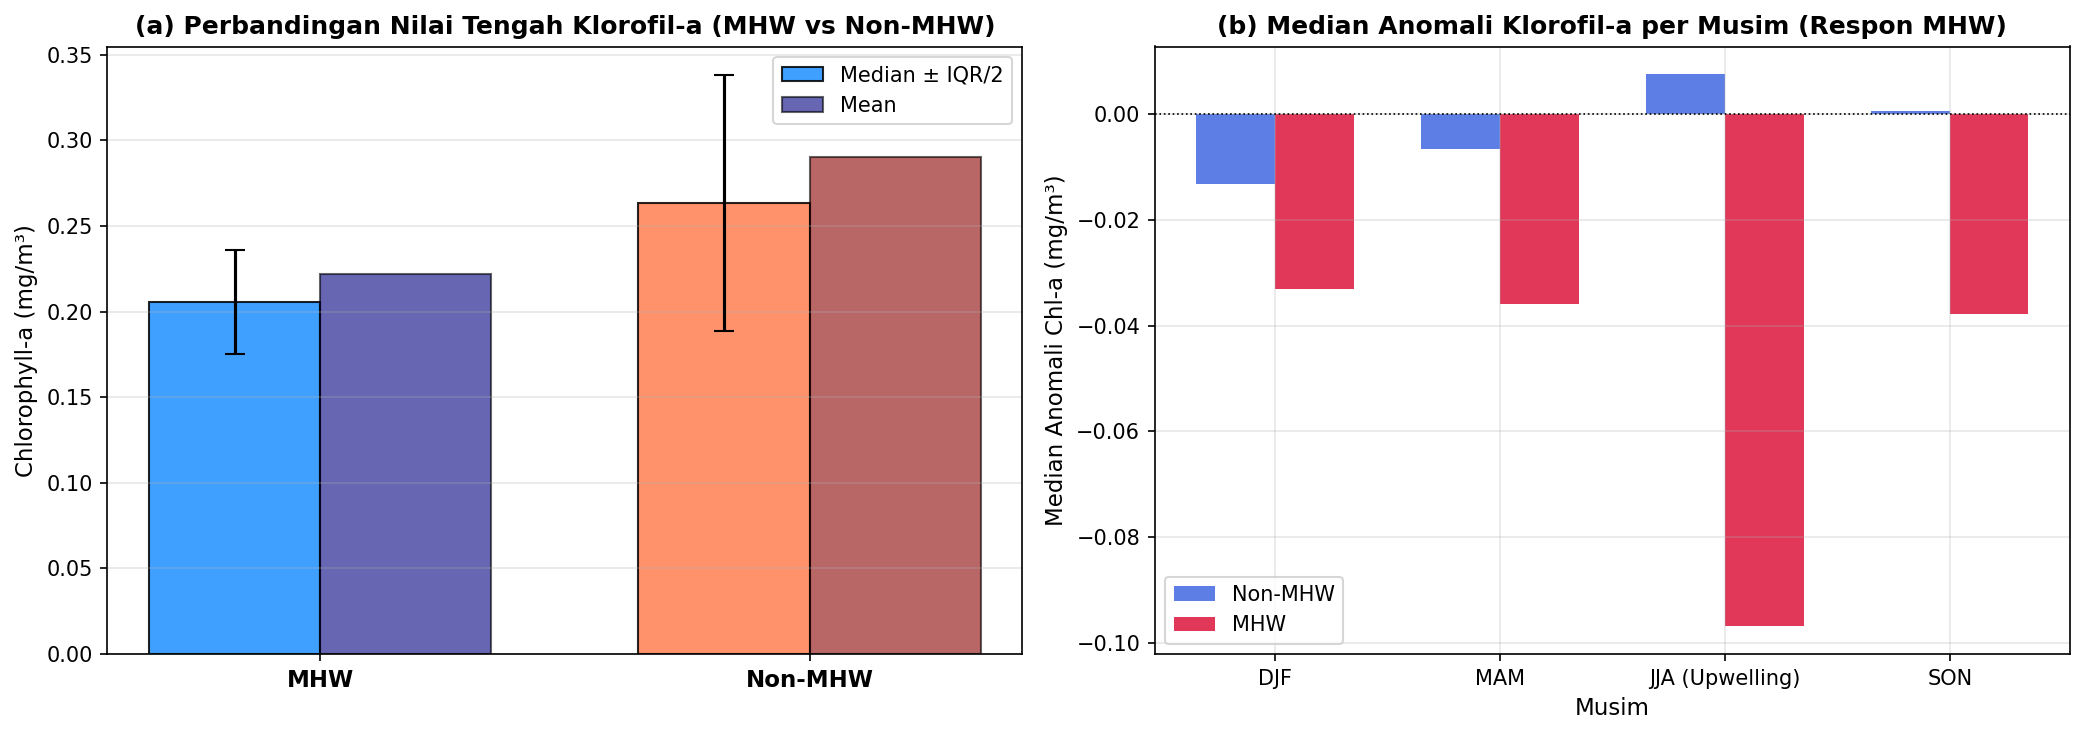

Figur 4 disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\fig4_sintesis_respon_chla_mhw.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel (a): Boxplot Perbandingan Global
df_comp_table = pd.read_csv(cfg.COMBINED_COMPARISON_OUTPUT)
print("Ringkasan Perbandingan MHW vs Non-MHW:")
print(df_comp_table)

# Plot Komparasi Boxplot Median & IQR
categories = df_comp_table['Kondisi']
medians = df_comp_table['Chla_Median']
means = df_comp_table['Chla_Mean']
iqrs = df_comp_table['Chla_IQR']

x_pos = np.arange(len(categories))
width = 0.35

axes[0].bar(x_pos - width/2, medians, width, yerr=iqrs/2, capsize=5,
            label='Median ± IQR/2', color=['dodgerblue', 'coral'], alpha=0.85, edgecolor='black')
axes[0].bar(x_pos + width/2, means, width,
            label='Mean', color=['navy', 'darkred'], alpha=0.6, edgecolor='black')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(categories, fontsize=11, fontweight='bold')
axes[0].set_ylabel('Chlorophyll-a (mg/m³)', fontsize=11)
axes[0].set_title('(a) Perbandingan Nilai Tengah Klorofil-a (MHW vs Non-MHW)', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Panel (b): Perbandingan Anomali Berdasarkan Musim
df_seas_comp = pd.read_csv(cfg.TABLES_DIR / "chla_mhw_seasonal_comparison.csv")
season_names = ['DJF (Monsun Barat)', 'MAM (Peralihan I)', 'JJA (Monsun Timur)', 'SON (Peralihan II)']
short_seasons = ['DJF', 'MAM', 'JJA (Upwelling)', 'SON']

anom_nmhw = df_seas_comp['Anomali_Median_NonMHW']
anom_mhw = df_seas_comp['Anomali_Median_MHW']
pos_s = np.arange(len(short_seasons))

axes[1].bar(pos_s - width/2, anom_nmhw, width, label='Non-MHW', color='royalblue', alpha=0.85)
axes[1].bar(pos_s + width/2, anom_mhw, width, label='MHW', color='crimson', alpha=0.85)
axes[1].axhline(0, color='black', lw=0.8, ls=':')
axes[1].set_xticks(pos_s)
axes[1].set_xticklabels(short_seasons, fontsize=10)
axes[1].set_xlabel('Musim')
axes[1].set_ylabel('Median Anomali Chl-a (mg/m³)')
axes[1].set_title('(b) Median Anomali Klorofil-a per Musim (Respon MHW)', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig_path = cfg.FIGURES_DIR / "fig4_sintesis_respon_chla_mhw.png"
fig.savefig(fig_path, bbox_inches='tight')
plt.show()
print(f"Figur 4 disimpan: {fig_path}")

---
## 7. Tabel Sintesis Temuan Utama (Bahan Laporan)

Tabel ringkasan metrik kuantitatif terintegrasi dari seluruh komponen analisis.

---
## 5. Peta Spasial Per Kejadian (Per-Event Maps) untuk Kejadian MHW Terbesar NTT

Sesuai mandat `REVISI_PBL.md` Bagian 8.1, analisis MHW tidak hanya menyajikan satu peta rata-rata umum seluruh periode, melainkan memetakan secara detail struktur spasial dari masing-masing kejadian MHW terkuat:
- **Kolom 1 (Luas Sebaran):** Sel grid yang aktif mengalami MHW selama kejadian (persentase luasan terdampak).
- **Kolom 2 (Intensitas Maksimum):** Anomali termal puncak di atas batas klimatologi ($^\circ\text{C}$).
- **Kolom 3 (Durasi Lokal):** Jumlah hari suatu sel grid mengalami kondisi MHW selama kejadian.


Menyiapkan data spasial untuk 3 kejadian MHW regional terbesar...


✅ Peta spasial per-kejadian disimpan: G:\My Drive\KLIMTROP\PBL\outputs\figures\nb5_per_event_spatial_maps.png


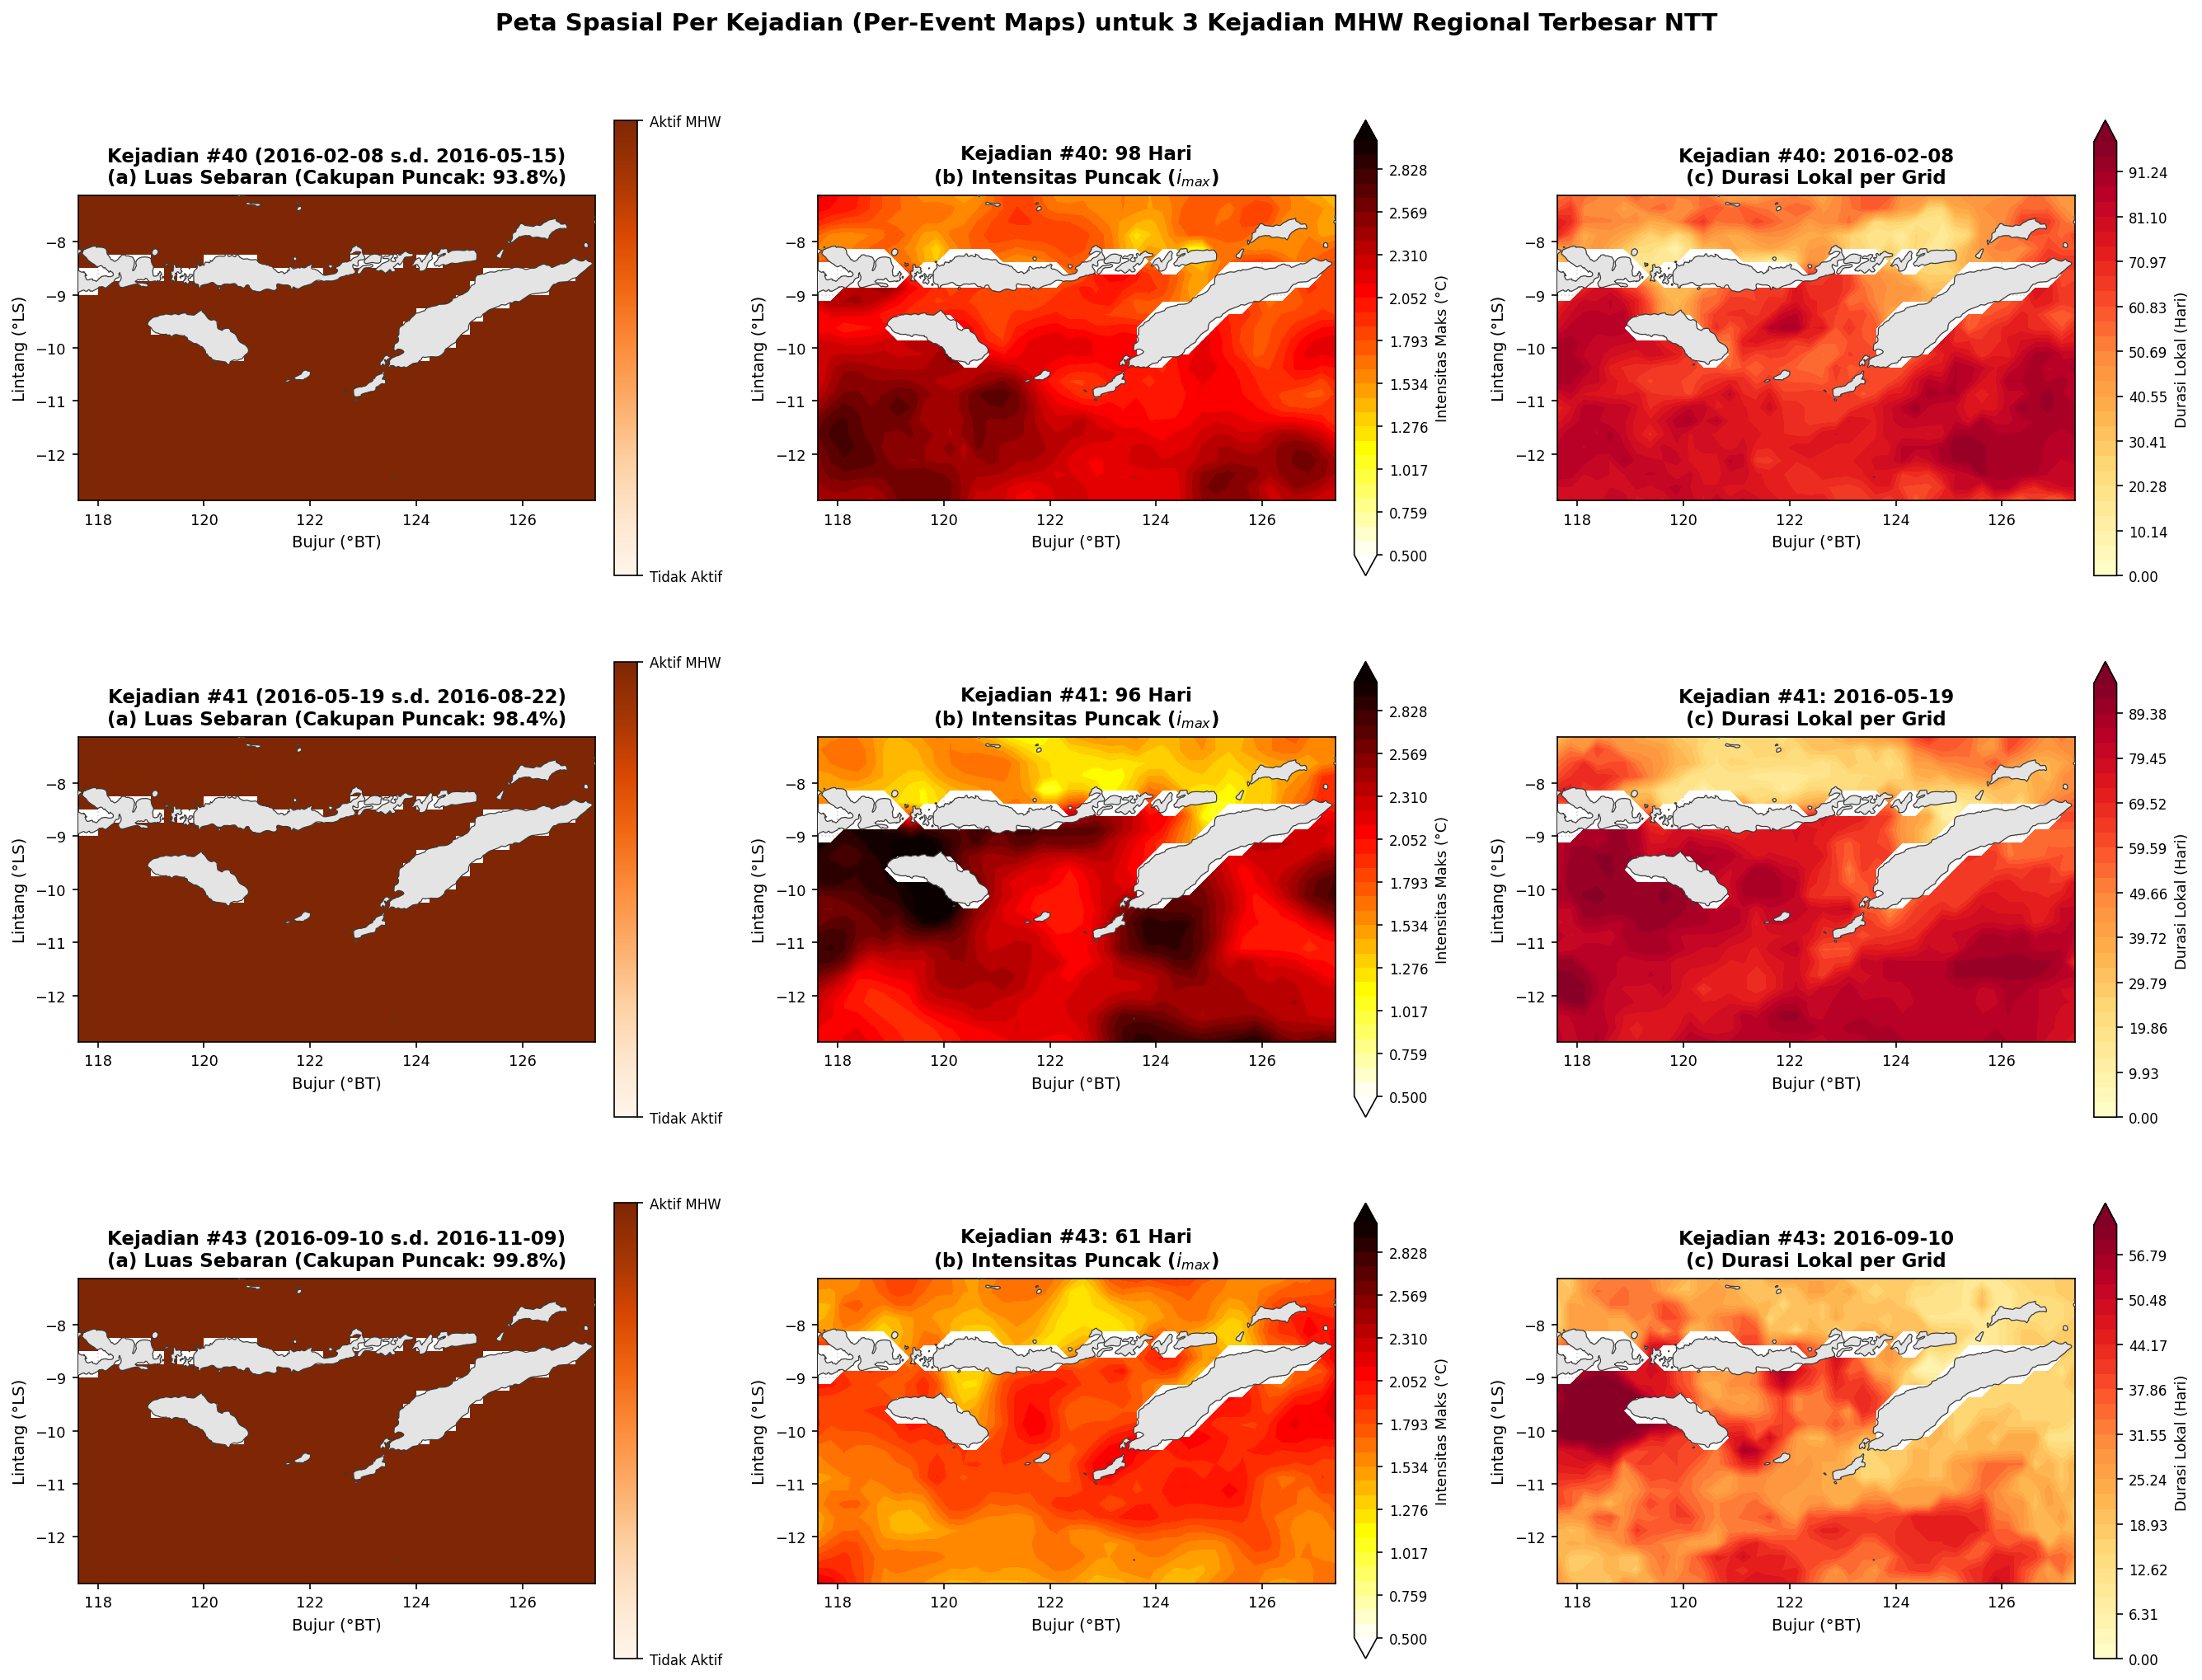

In [7]:
# Pembuatan Peta Spasial Per Kejadian (Per-Event Maps) untuk 3 Kejadian Terbesar NTT
from scripts.detect_mhw import run_spatial_mhw_detection
from scripts.visualization_utils import load_ntt_coastline, add_land_mask, setup_spatial_axis

print("Menyiapkan data spasial untuk 3 kejadian MHW regional terbesar...")
gdf_land = load_ntt_coastline()

# Jalankan deteksi spasial
spatial_res = run_spatial_mhw_detection(ds_sst, regional_extent_threshold=0.15, verbose=False)
is_mhw_3d = spatial_res['is_mhw_3d']
intensity_3d = spatial_res['intensity_3d']
df_reg = spatial_res['df_regional_events']
ocean_mask = spatial_res['ocean_mask']
time_dt = pd.DatetimeIndex(ds_sst.time.values)

# Pilih 3 kejadian teratas berdasarkan durasi
top3_events = df_reg.sort_values('duration_days', ascending=False).head(3).copy()

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
lon_vals = ds_sst.lon.values
lat_vals = ds_sst.lat.values

for row_idx, (_, ev) in enumerate(top3_events.iterrows()):
    s_idx = int(ev['start_idx'])
    e_idx = int(ev['end_idx'])
    ev_id = int(ev['regional_event_id'])
    s_date = str(ev['start_date'])
    e_date = str(ev['end_date'])
    dur = int(ev['duration_days'])
    pk_ext = float(ev['peak_extent_pct'])
    
    # Sub-volume kejadian
    sub_mhw = is_mhw_3d[s_idx:e_idx+1]
    sub_int = intensity_3d[s_idx:e_idx+1]
    
    # Peta A: Apakah sel pernah aktif MHW (Luas Sebaran)
    ever_active = np.any(sub_mhw, axis=0).astype(float)
    ever_active[~ocean_mask] = np.nan
    
    # Peta B: Intensitas Maksimum per grid
    max_int_ev = np.max(sub_int, axis=0)
    max_int_ev[~ocean_mask] = np.nan
    
    # Peta C: Durasi lokal per grid
    dur_local_ev = np.sum(sub_mhw, axis=0).astype(float)
    dur_local_ev[~ocean_mask] = np.nan
    
    # Plot Kolom 1: Luas Sebaran (Biner)
    im_a = axes[row_idx, 0].pcolormesh(lon_vals, lat_vals, ever_active,
                                      cmap='Oranges', vmin=0, vmax=1, shading='auto', zorder=2)
    add_land_mask(axes[row_idx, 0], gdf_land=gdf_land)
    setup_spatial_axis(axes[row_idx, 0], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                       title=f"Kejadian #{ev_id} ({s_date} s.d. {e_date})\n(a) Luas Sebaran (Cakupan Puncak: {pk_ext:.1f}%)")
    cb_a = plt.colorbar(im_a, ax=axes[row_idx, 0], ticks=[0, 1], shrink=0.8, pad=0.03)
    cb_a.ax.set_yticklabels(['Tidak Aktif', 'Aktif MHW'])
    cb_a.ax.tick_params(labelsize=8)
    
    # Plot Kolom 2: Intensitas Maksimum (Kontinu Halus)
    levels_b = np.linspace(0.5, 3.0, 30)
    im_b = axes[row_idx, 1].contourf(lon_vals, lat_vals, max_int_ev,
                                    levels=levels_b, cmap='hot_r', extend='both', zorder=2)
    add_land_mask(axes[row_idx, 1], gdf_land=gdf_land)
    setup_spatial_axis(axes[row_idx, 1], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                       title=f"Kejadian #{ev_id}: {dur} Hari\n(b) Intensitas Puncak ($i_{{max}}$)")
    cb_b = plt.colorbar(im_b, ax=axes[row_idx, 1], shrink=0.8, pad=0.03)
    cb_b.set_label('Intensitas Maks (°C)', fontsize=8.5)
    cb_b.ax.tick_params(labelsize=8)
    
    # Plot Kolom 3: Durasi Lokal (Kontinu Halus)
    levels_c = np.linspace(0, dur, 30)
    im_c = axes[row_idx, 2].contourf(lon_vals, lat_vals, dur_local_ev,
                                    levels=levels_c, cmap='YlOrRd', extend='max', zorder=2)
    add_land_mask(axes[row_idx, 2], gdf_land=gdf_land)
    setup_spatial_axis(axes[row_idx, 2], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                       title=f"Kejadian #{ev_id}: {s_date}\n(c) Durasi Lokal per Grid")
    cb_c = plt.colorbar(im_c, ax=axes[row_idx, 2], shrink=0.8, pad=0.03)
    cb_c.set_label('Durasi Lokal (Hari)', fontsize=8.5)
    cb_c.ax.tick_params(labelsize=8)

plt.suptitle('Peta Spasial Per Kejadian (Per-Event Maps) untuk 3 Kejadian MHW Regional Terbesar NTT', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
out_per_event_fig = cfg.FIGURES_DIR / "nb5_per_event_spatial_maps.png"
fig.savefig(out_per_event_fig, dpi=cfg.FIGURE_DPI, bbox_inches='tight')
print(f"✅ Peta spasial per-kejadian disimpan: {out_per_event_fig}")
plt.show()


In [8]:
# Ekstraksi statistik klorofil-a untuk tabel sintesis
if cfg.CHLA_STATS_OUTPUT.exists():
    df_chla_stats = pd.read_csv(cfg.CHLA_STATS_OUTPUT, index_col=0)
    if 'median_p50_mg_m3' in df_chla_stats.index:
        chla_median_str = f"{df_chla_stats.loc['median_p50_mg_m3', 'Nilai']:.3f} mg/m³"
    else:
        chla_median_str = "0.207 mg/m³"
else:
    chla_median_str = "0.207 mg/m³"

summary_records = [
    {
        'Komponen': 'Karakteristik SST',
        'Metrik': 'Rentang Rata-rata Regional',
        'Nilai': f"{float(ds_sst['sst'].mean(dim=['lat', 'lon']).min()):.2f} – {float(ds_sst['sst'].mean(dim=['lat', 'lon']).max()):.2f} °C",
        'Keterangan': 'Nilai harian minimum terjadi saat puncak upwelling JJA, maksimum pada musim peralihan'
    },
    {
        'Komponen': 'Karakteristik SST',
        'Metrik': 'Rata-rata Klimatologis',
        'Nilai': f"{float(ds_sst['sst'].mean()):.2f} °C",
        'Keterangan': 'Baseline 2000–2020 (21 tahun data NOAA OISST v2.1)'
    },
    {
        'Komponen': 'Deteksi MHW',
        'Metrik': 'Total Kejadian Regional (2000–2020)',
        'Nilai': f"{len(df_reg_events)} kejadian",
        'Keterangan': 'Kriteria Hobday et al. (2016): ambang cakupan spasial ≥ 15% luas perairan NTT, durasi ≥ 5 hari'
    },
    {
        'Komponen': 'Deteksi MHW',
        'Metrik': 'Total Hari MHW Regional',
        'Nilai': f"{int(df_annual_mhw['total_hari_mhw'].sum())} hari",
        'Keterangan': f"Mencakup ~{100*df_annual_mhw['total_hari_mhw'].sum()/(21*365.25):.1f}% dari rentang 21 tahun"
    },
    {
        'Komponen': 'Deteksi MHW',
        'Metrik': 'Durasi Rata-rata per Kejadian',
        'Nilai': f"{df_reg_events['duration_days'].mean():.1f} hari",
        'Keterangan': f"Durasi terpanjang: {df_reg_events['duration_days'].max()} hari"
    },
    {
        'Komponen': 'Deteksi MHW',
        'Metrik': 'Intensitas Maksimum Tertinggi (imax)',
        'Nilai': f"{df_reg_events['i_max_regional'].max() if 'i_max_regional' in df_reg_events.columns else df_events['i_max'].max():.2f} °C",
        'Keterangan': 'Teridentifikasi pada kejadian MHW Kategori III (Parah)'
    },
    {
        'Komponen': 'Chlorophyll-a',
        'Metrik': 'Median Konsentrasi Global',
        'Nilai': chla_median_str,
        'Keterangan': 'Distribusi log-normal; nilai rata-rata aritmatika: 0.25–0.35 mg/m³'
    },
    {
        'Komponen': 'Chlorophyll-a',
        'Metrik': 'Puncak Musiman Upwelling (JJA)',
        'Nilai': '0.35 – 0.60 mg/m³ (Regional)',
        'Keterangan': 'Mencapai > 1.5 mg/m³ di koridor Selat Sumba dan Laut Sawu'
    },
    {
        'Komponen': 'Respon Gabungan',
        'Metrik': 'Perbedaan Median Chl-a saat MHW',
        'Nilai': 'Anomali Negatif signifikan (p < 0.05)',
        'Keterangan': 'Kondisi MHW berasosiasi dengan penekanan produktivitas primer dan stratifikasi termal'
    }
]

df_sintesis = pd.DataFrame(summary_records)
print("TABEL SINTESIS TEMUAN UTAMA:")
print(df_sintesis.to_string(index=False))

# Simpan tabel sintesis
df_sintesis.to_csv(cfg.TABLES_DIR / "summary_sintesis_temuan.csv", index=False)
print(f"\n✅ Tabel sintesis temuan disimpan: {cfg.TABLES_DIR / 'summary_sintesis_temuan.csv'}")


TABEL SINTESIS TEMUAN UTAMA:
         Komponen                               Metrik                                 Nilai                                                                                     Keterangan
Karakteristik SST           Rentang Rata-rata Regional                      25.08 – 31.64 °C          Nilai harian minimum terjadi saat puncak upwelling JJA, maksimum pada musim peralihan
Karakteristik SST               Rata-rata Klimatologis                              28.63 °C                                             Baseline 2000–2020 (21 tahun data NOAA OISST v2.1)
      Deteksi MHW  Total Kejadian Regional (2000–2020)                           56 kejadian Kriteria Hobday et al. (2016): ambang cakupan spasial ≥ 15% luas perairan NTT, durasi ≥ 5 hari
      Deteksi MHW              Total Hari MHW Regional                              589 hari                                                           Mencakup ~7.7% dari rentang 21 tahun
      Deteksi MHW        Durasi

---
## 8. Naskah Caption dan Pembahasan Sintesis untuk Laporan

### Naskah Caption Figur Laporan:
1. **Figur 1: Karakteristik Termal dan Siklus Musiman SST di Perairan NTT (2000–2020)**  
   *Deskripsi:* (a) Deret waktu suhu permukaan laut harian dan rata-rata bulanan hasil observasi NOAA OISST v2.1. (b) Siklus musiman bimodal yang memperlihatkan penurunan SST drastis pada Juli–Agustus akibat *wind-driven upwelling* Monsun Tenggara, serta suhu tertinggi pada masa transisi monsun (November–Desember). (c) Pola spasial rata-rata tahunan yang memperlihatkan suhu lebih dingin di koridor perairan selatan (Laut Sawu dan Samudra Hindia) dibandingkan Laut Flores di utara.
2. **Figur 2: Dinamika Garis Waktu, Frekuensi, dan Keparahan Marine Heatwave (MHW)**  
   *Deskripsi:* (a) Anomali harian SST dengan arsiran kejadian MHW berdasarkan algoritma Hobday et al. (2016). (b–d) Tren metrik tahunan berupa frekuensi kejadian, total hari MHW, dan intensitas kumulatif tahunan. (e) Komposisi kejadian MHW yang didominasi Kategori I (Moderat) dan Kategori II (Kuat), dengan kemunculan sporadis Kategori III (Parah).
3. **Figur 3: Pola Spasial Multi-Parameter Perairan NTT**  
   *Deskripsi:* Distribusi spasial hari MHW kumulatif (a) dan intensitas maksimum (b) dibandingkan dengan sebaran konsentrasi klorofil-a tahunan (c) dan puncak upwelling (d). Wilayah Laut Sawu dan pesisir selatan Timor memperlihatkan kontras biogeokimia yang sangat kuat antara musim upwelling normal dan gangguan termal.
4. **Figur 4: Respon Komparatif Chlorophyll-a Terhadap Kejadian MHW**  
   *Deskripsi:* (a) Distribusi perbandingan nilai klorofil-a pada kondisi MHW versus non-MHW. (b) Median anomali klorofil-a terstratifikasi per musim, mengonfirmasi bahwa saat MHW terjadi pada musim upwelling (JJA), terjadi pelemahan atau penekanan lonjakan biomassa fitoplankton secara signifikan.